**DeathCountbyCDAgeandCause_Scatterplot**


In [1]:
import geopandas as gpd

print("GeoPandas installed successfully!")
print("Version:", gpd.__version__)

GeoPandas installed successfully!
Version: 1.2.0


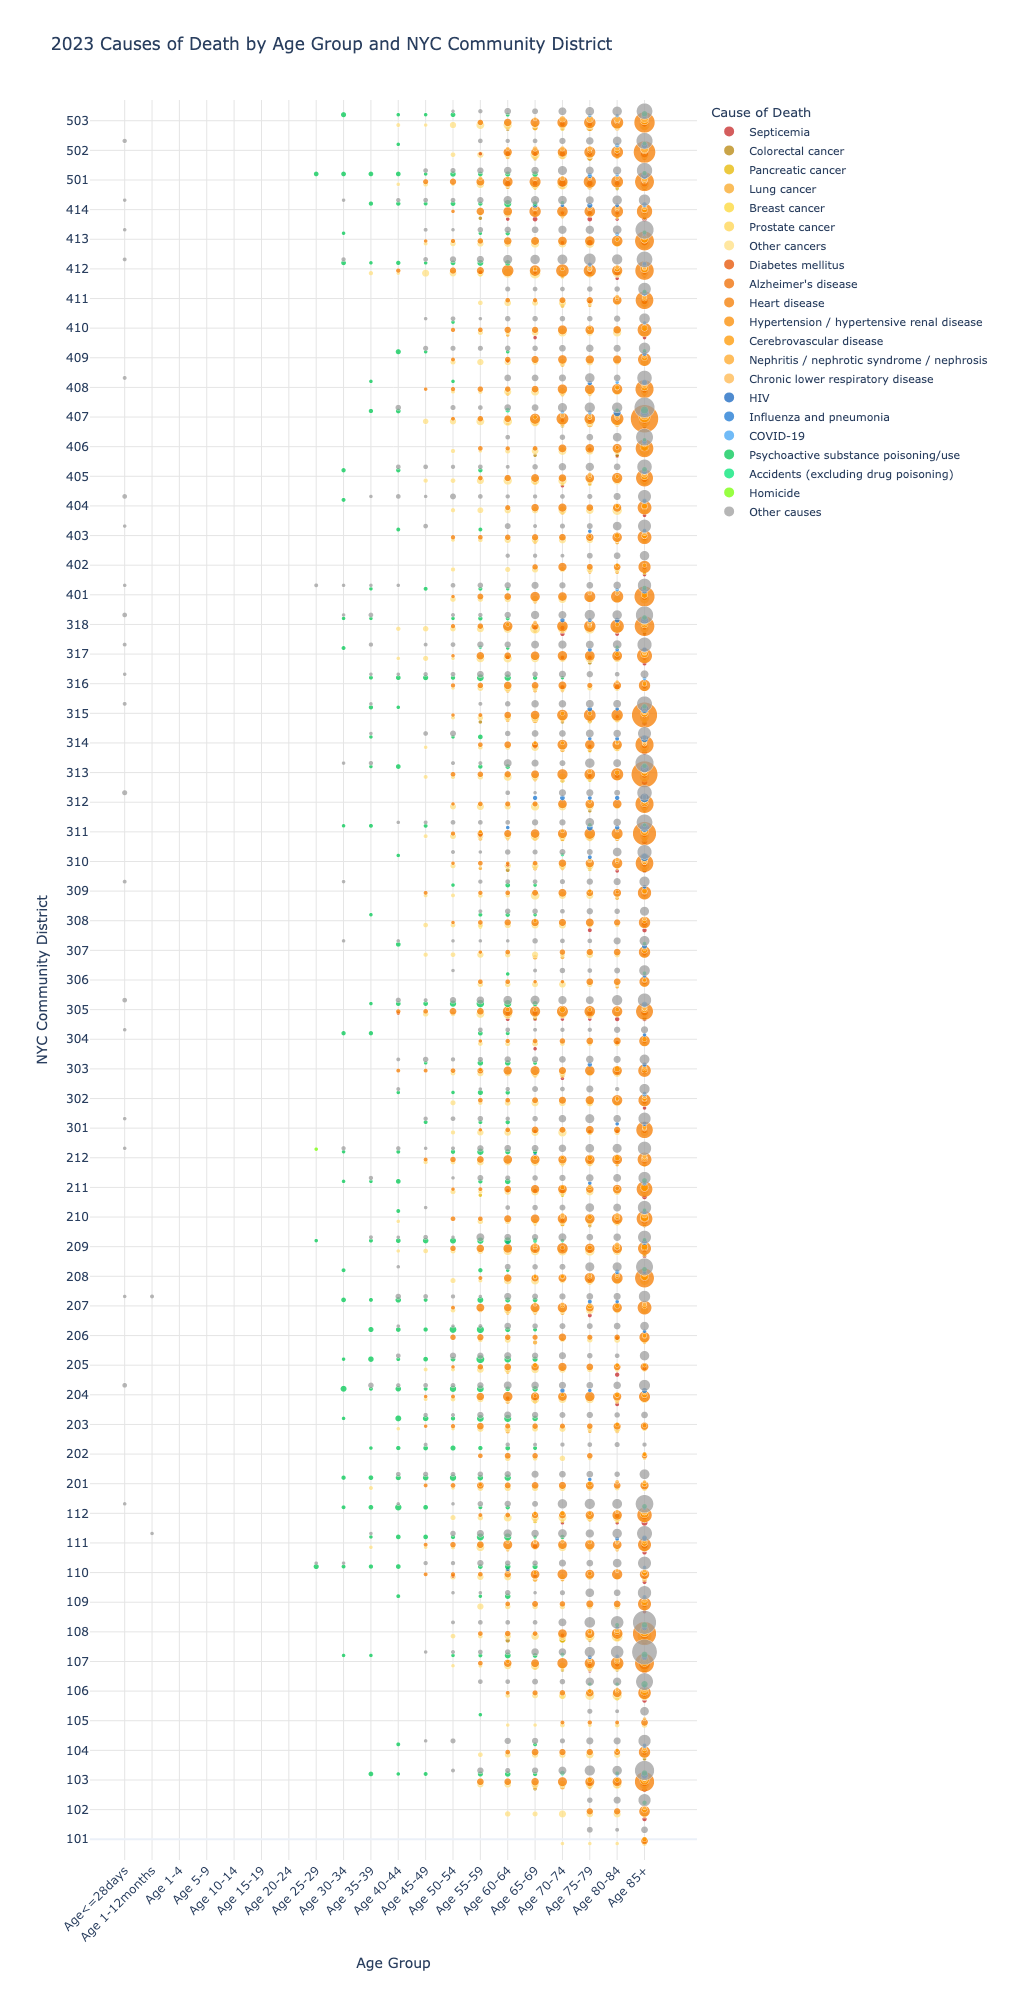

In [3]:

import pandas as pd
import numpy as np
import plotly.express as px

# LOAD DATA

df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")
df.columns = df.columns.str.strip()

# DEFINE AGE GROUPS

age_groups = [
    "Age<=28days",
    "Age 1-12months",
    "Age 1-4",
    "Age 5-9",
    "Age 10-14",
    "Age 15-19",
    "Age 20-24",
    "Age 25-29",
    "Age 30-34",
    "Age 35-39",
    "Age 40-44",
    "Age 45-49",
    "Age 50-54",
    "Age 55-59",
    "Age 60-64",
    "Age 65-69",
    "Age 70-74",
    "Age 75-79",
    "Age 80-84",
    "Age 85+"
]

# CAUSE-OF-DEATH LABELS

cause_labels = {
    "Deaths due to septicemia": "Septicemia",
    "Deaths due to HIV": "HIV",
    "Deaths due to malignant neoplasms(cancer)": "Cancer (all malignant neoplasms)",
    "Deaths due to cancer of the colon_ rectum_ and anus": "Colorectal cancer",
    "Deaths due to cancer of the pancreas": "Pancreatic cancer",
    "Deaths due to cancer of trachea_ bronchus_ and lung": "Lung cancer",
    "Deaths due to cancer of the breast": "Breast cancer",
    "Deaths due to cancer of the prostate": "Prostate cancer",
    "Deaths due to diabetes mellitus": "Diabetes mellitus",
    "Deaths due to use of or poisoning by psychoactive substance excluding alcohol and tobacco": "Psychoactive substance poisoning/use",
    "Deaths due to Alzheimer's disease": "Alzheimer's disease",
    "Deaths due to diseases of the heart": "Heart disease",
    "Deaths due to essential hypertension and hypertensive renal disease": "Hypertension / hypertensive renal disease",
    "Deaths due to cerebrovascular diseases": "Cerebrovascular disease",
    "Deaths due to influenza and pneumonia": "Influenza and pneumonia",
    "Deaths due to chronic lower respiratory diseases": "Chronic lower respiratory disease",
    "Deaths due to chronic liver disease and cirrhosis": "Chronic liver disease / cirrhosis",
    "Deaths due to Nephritis_ Nephrotic Syndrome and Nephrosis": "Nephritis / nephrotic syndrome / nephrosis",
    "Deaths due to Covid19": "COVID-19",
    "Deaths due to accidents except for durg poisoning": "Accidents (excluding drug poisoning)",
    "Deaths due to intentional self-harm(suicide)": "Suicide",
    "Deaths due to assault(homicide)": "Homicide",
    "Other causes": "Other causes"
}

# SAME CUSTOM COLOR PALETTE

cause_color_map = {
    # RED - SEPTICEMIA
    "Septicemia": "#C62828",

    # YELLOW - CANCERS
    "Colorectal cancer": "#B8860B",
    "Pancreatic cancer": "#E6B800",
    "Lung cancer": "#F9A825",
    "Breast cancer": "#FDD835",
    "Prostate cancer": "#FFD54F",
    "Other cancers": "#FFE082",

    # ORANGE - CHRONIC DISEASES
    "Diabetes mellitus": "#E65100",
    "Alzheimer's disease": "#EF6C00",
    "Heart disease": "#F57C00",
    "Hypertension / hypertensive renal disease": "#FB8C00",
    "Cerebrovascular disease": "#FF9800",
    "Nephritis / nephrotic syndrome / nephrosis": "#FFA726",
    "Chronic lower respiratory disease": "#FFB74D",
    "Chronic liver disease / cirrhosis": "#FFCC80",

    # BLUE - INFECTIOUS DISEASES
    "HIV": "#1565C0",
    "Influenza and pneumonia": "#1976D2",
    "COVID-19": "#42A5F5",

    # GREEN - NON-NATURAL DEATHS
    "Psychoactive substance poisoning/use": "#00C853",
    "Accidents (excluding drug poisoning)": "#00E676",
    "Suicide": "#43A047",
    "Homicide": "#76FF03",

    # GREY - OTHER CAUSES
    "Other causes": "#9E9E9E"
}

# FIND CAUSE-BY-AGE COLUMNS
 

age_cause_columns = {}

for cause in cause_labels:
    age_cause_columns[cause] = [
        f"{cause}_{age}"
        for age in age_groups
    ]

# Validate columns before proceeding
missing = [
    col
    for cols in age_cause_columns.values()
    for col in cols
    if col not in df.columns
]

if missing:
    print("Missing cause-by-age columns:")
    print(*missing[:40], sep="\n")
    raise ValueError(
        "Some column names do not match the expected "
        "cause-by-age naming convention. "
        "Inspect df.columns to identify the differences."
    )

# RESHAPE TO LONG FORMAT 

records = []

for cause, columns in age_cause_columns.items():

    for age, col in zip(age_groups, columns):

        temp = df[["commntydst", col]].copy()

        temp["Count"] = pd.to_numeric(
            temp[col].astype(str).str.replace(
                ",", "", regex=False
            ),
            errors="coerce"
        ).fillna(0)

        temp["Age Group"] = age
        temp["Cause"] = cause_labels[cause]

        records.append(
            temp[["commntydst", "Age Group", "Cause", "Count"]]
        )

df_long = pd.concat(records, ignore_index=True)

# Clean district codes
df_long["commntydst"] = (
    df_long["commntydst"].astype(str).str.strip()
)

# Aggregate counts if districts have multiple rows
df_long = df_long.groupby(
    ["commntydst", "Age Group", "Cause"],
    as_index=False
)["Count"].sum()

# CALCULATE OTHER CANCERS BY AGE

cancer_causes = [
    "Colorectal cancer",
    "Pancreatic cancer",
    "Lung cancer",
    "Breast cancer",
    "Prostate cancer"
]

# Total cancer deaths by district and age
all_cancers = df_long[
    df_long["Cause"] == "Cancer (all malignant neoplasms)"
][["commntydst", "Age Group", "Count"]].rename(
    columns={"Count": "All_Cancers"}
)

# Sum site-specific cancer deaths
specific_cancers = (
    df_long[df_long["Cause"].isin(cancer_causes)]
    .groupby(["commntydst", "Age Group"], as_index=False)
    ["Count"].sum()
    .rename(columns={"Count": "Specific_Cancers"})
)

# Calculate residual cancer deaths
other_cancers = all_cancers.merge(
    specific_cancers,
    on=["commntydst", "Age Group"],
    how="left"
)

other_cancers["Specific_Cancers"] = (
    other_cancers["Specific_Cancers"].fillna(0)
)

other_cancers["Count"] = (
    other_cancers["All_Cancers"]
    - other_cancers["Specific_Cancers"]
)

if (other_cancers["Count"] < 0).any():
    raise ValueError(
        "Site-specific cancer counts exceed total cancer "
        "counts for some district-age combinations."
    )

other_cancers["Cause"] = "Other cancers"

other_cancers = other_cancers[
    ["commntydst", "Age Group", "Cause", "Count"]
]

# Remove overall cancer total to avoid double-counting
df_long = df_long[
    df_long["Cause"] != "Cancer (all malignant neoplasms)"
].copy()

# Add Other cancers
df_long = pd.concat(
    [df_long, other_cancers],
    ignore_index=True
)


df_long = df_long[df_long["Count"] > 0].copy()


districts = sorted(
    df_long["commntydst"].unique(),
    key=lambda x: (
        0, int(x)
    ) if x.isdigit() else (1, x)
)

age_order = age_groups

 
district_positions = {
    district: i
    for i, district in enumerate(districts)
}

df_long["District_Position"] = (
    df_long["commntydst"].map(district_positions)
)
 
cause_order = list(cause_color_map.keys())

offsets = np.linspace(
    -0.32, 0.32, len(cause_order)
)

cause_offsets = dict(zip(cause_order, offsets))

df_long["Y_Position"] = (
    df_long["District_Position"]
    + df_long["Cause"].map(cause_offsets)
)

# CREATE BUBBLE SCATTER PLOT
fig = px.scatter(
    df_long,
    x="Age Group",
    y="Y_Position",
    size="Count",
    color="Cause",

    color_discrete_map=cause_color_map,

    category_orders={
        "Age Group": age_order,
        "Cause": cause_order
    },

    custom_data=[
        "commntydst",
        "Age Group",
        "Cause",
        "Count"
    ],

    size_max=28,

    title=(
        "2023 Causes of Death by Age Group "
        "and NYC Community District"
    ),

    height=2000
)

# CUSTOMIZE HOVER INFORMATION

fig.update_traces(
    hovertemplate=(
        "<b>Community District:</b> %{customdata[0]}<br>"
        "<b>Age Group:</b> %{customdata[1]}<br>"
        "<b>Cause of Death:</b> %{customdata[2]}<br>"
        "<b>Death Count:</b> %{customdata[3]:,.0f}"
        "<extra></extra>"
    ),
    marker=dict(
        opacity=0.75,
        line=dict(
            width=0.5,
            color="white"
        )
    )
)

# CUSTOMIZE AXES AND LAYOUT

fig.update_layout(
    xaxis_title="Age Group",
    yaxis_title="NYC Community District",
    legend_title="Cause of Death",
    template="plotly_white",
    hovermode="closest",

    height=2000,

    legend=dict(
        orientation="v",
        x=1.02,
        y=1,
        font=dict(size=11),
        itemsizing="constant"
    ),

    margin=dict(
        l=90,
        r=320,
        t=100,
        b=140
    )
)

# Show district codes instead of numeric positions
fig.update_yaxes(
    tickmode="array",
    tickvals=list(range(len(districts))),
    ticktext=districts,
    range=[-0.7, len(districts) - 0.3],
    showgrid=True,
    gridcolor="#E5E5E5"
)

fig.update_xaxes(
    categoryorder="array",
    categoryarray=age_order,
    tickangle=-45,
    showgrid=True,
    gridcolor="#E5E5E5"
)

fig.show()


In [6]:
import pandas as pd

causes_df = pd.read_csv("CommunityDistrictSingleYearCounts2023.csv")

print(causes_df.columns.tolist())
display(causes_df.head(3))

['commntydst', 'Male', 'Female', 'Age<=28days', 'Age 1-12months', 'Age 1-4', 'Age 5-9', 'Age 10-14', 'Age 15-19', 'Age 20-24', 'Age 25-29', 'Age 30-34', 'Age 35-39', 'Age 40-44', 'Age 45-49', 'Age 50-54', 'Age 55-59', 'Age 60-64', 'Age 65-69', 'Age 70-74', 'Age 75-79', 'Age 80-84', 'Age 85+', 'Age Unkown', 'Male_Age<=28days', 'Male_Age 1-12months', 'Male_Age 1-4', 'Male_Age 5-9', 'Male_Age 10-14', 'Male_Age 15-19', 'Male_Age 20-24', 'Male_Age 25-29', 'Male_Age 30-34', 'Male_Age 35-39', 'Male_Age 40-44', 'Male_Age 45-49', 'Male_Age 50-54', 'Male_Age 55-59', 'Male_Age 60-64', 'Male_Age 65-69', 'Male_Age 70-74', 'Male_Age 75-79', 'Male_Age 80-84', 'Male_Age 85+', 'Male_Age Unkown', 'Female_Age<=28days', 'Female_Age 1-12months', 'Female_Age 1-4', 'Female_Age 5-9', 'Female_Age 10-14', 'Female_Age 15-19', 'Female_Age 20-24', 'Female_Age 25-29', 'Female_Age 30-34', 'Female_Age 35-39', 'Female_Age 40-44', 'Female_Age 45-49', 'Female_Age 50-54', 'Female_Age 55-59', 'Female_Age 60-64', 'Female_A

,commntydst,Male,Female,Age<=28days,Age 1-12months,Age 1-4,Age 5-9,Age 10-14,Age 15-19,Age 20-24,...,Deaths due to assault(homicide)_Hispanic,Deaths due to assault(homicide)_Asian Non-Hispanic,Deaths due to assault(homicide)_White Non-Hispanic,Deaths due to assault(homicide)_Black Non-Hispanic,Deaths due to assault(homicide)_Other race/ethnicity or not known,Other causes_Hispanic,Other causes_Asian Non-Hispanic,Other causes_White Non-Hispanic,Other causes_Black Non-Hispanic,Other causes_Other race/ethnicity or not known
0,101,85,85,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,28.0,NaN,NaN
1,102,204,183,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,8.0,12.0,76.0,NaN,5.0
2,103,599,581,NaN,NaN,NaN,NaN,NaN,NaN,7.0,...,NaN,NaN,NaN,NaN,NaN,77.0,101.0,71.0,22.0,8.0


In [8]:
print(df_long.columns.tolist())

['commntydst', 'Age Group', 'Cause', 'Count', 'District_Position', 'Y_Position']


In [10]:
import pandas as pd
import numpy as np

# Load the original dataset
causes_df = pd.read_csv(
    "CommunityDistrictSingleYearCounts2023.csv"
)

# Identify cause-of-death columns
cause_columns = list(cause_labels.keys())

# Check that the expected columns exist
missing = [
    col for col in cause_columns
    if col not in causes_df.columns
]

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Convert death counts to numeric values
for col in cause_columns:
    causes_df[col] = pd.to_numeric(
        causes_df[col].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    ).fillna(0)

# Standardize community district identifiers
causes_df["commntydst"] = (
    causes_df["commntydst"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
)

# Calculate Other cancers
all_cancer_col = "Deaths due to malignant neoplasms(cancer)"

specific_cancer_cols = [
    "Deaths due to cancer of the colon_ rectum_ and anus",
    "Deaths due to cancer of the pancreas",
    "Deaths due to cancer of trachea_ bronchus_ and lung",
    "Deaths due to cancer of the breast",
    "Deaths due to cancer of the prostate"
]

causes_df["Other cancers"] = (
    causes_df[all_cancer_col]
    - causes_df[specific_cancer_cols].sum(axis=1)
)

if (causes_df["Other cancers"] < 0).any():
    raise ValueError(
        "Negative Other cancers counts detected."
    )

# Exclude overall cancer total to avoid double-counting
chart_columns = [
    col for col in cause_columns
    if col != all_cancer_col
]

chart_columns.append("Other cancers")

# Aggregate counts by community district
df_grouped = causes_df.groupby(
    "commntydst",
    as_index=False
)[chart_columns].sum()

# Rebuild df_long
df_long = df_grouped.melt(
    id_vars="commntydst",
    value_vars=chart_columns,
    var_name="Cause of Death",
    value_name="Count"
)

# Create readable cause labels
df_long["Cause Label"] = (
    df_long["Cause of Death"].map(cause_labels)
)

df_long.loc[
    df_long["Cause of Death"] == "Other cancers",
    "Cause Label"
] = "Other cancers"

# Calculate percentages
df_long["District_Total"] = (
    df_long.groupby("commntydst")["Count"]
    .transform("sum")
)

df_long["Percentage"] = (
    df_long["Count"]
    / df_long["District_Total"].replace(0, np.nan)
    * 100
).fillna(0)

# Verify the result
print("Columns:", df_long.columns.tolist())
print("Number of districts:", df_long["commntydst"].nunique())

display(df_long.head(10))

Columns: ['commntydst', 'Cause of Death', 'Count', 'Cause Label', 'District_Total', 'Percentage']
Number of districts: 59


/var/folders/pl/hh80xm6x4hvcgdgydq01cwt00000gn/T/ipykernel_5125/658797269.py:47: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  causes_df["Other cancers"] = (


,commntydst,Cause of Death,Count,Cause Label,District_Total,Percentage
0,101,Deaths due to septicemia,0.0,Septicemia,153.0,0.000000
1,102,Deaths due to septicemia,10.0,Septicemia,374.0,2.673797
2,103,Deaths due to septicemia,21.0,Septicemia,1177.0,1.784197
3,104,Deaths due to septicemia,8.0,Septicemia,570.0,1.403509
4,105,Deaths due to septicemia,5.0,Septicemia,211.0,2.369668
5,106,Deaths due to septicemia,15.0,Septicemia,709.0,2.115656
6,107,Deaths due to septicemia,21.0,Septicemia,1399.0,1.501072
7,108,Deaths due to septicemia,17.0,Septicemia,1325.0,1.283019
8,109,Deaths due to septicemia,15.0,Septicemia,574.0,2.613240
9,110,Deaths due to septicemia,13.0,Septicemia,856.0,1.518692
